In [1]:
import os, warnings
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)  # run from the project root so data/ paths resolve
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from cifresignificative.analysis.data import *
from cifresignificative.viz.style import *
apply_style()
panel = load_panel()


# Industry panel: does growth load on ICT- or intangible-intensive industries, and where is Italy?
Country-level screens rest on about 30 countries. Here the unit is **country x industry** (about 57 market industries at 2-digit level per country, `sectors64`), which gives thousands of observations, while the *country* remains the unit of judgement.
Design (Rajan-Zingales style): outcome = log growth per year of real value added per hour (mean 2005-07 to mean 2017-19; early and late halves as split-sample checks), winsorised at 1% / 99%. Industry intensity = contribution of ICT (or intangible) capital to labour productivity growth in the industry's EU KLEMS section, **median over the other countries, 1996-2004** (Italy left out, and before the outcome window). For each country: slope of growth on intensity.
Inference: the intensity varies only between ~14 sections, so a clustered t-test over-rejects (a shuffled-intensity check showed 15-20% false positives); p-values come from **permuting the intensity across sections**, and Italy is judged by its **rank among countries** (placebo ranking), never by a clustered test. Coverage: hours at 2-digit level are missing for several countries (Germany, France, Belgium, Portugal and others have 15 industries or fewer), so about 19 countries enter.
**Association only, never causal.** Code: `src/cifresignificative/analysis/industry_panel.py`, `experiments.run_industry_all`.

In [2]:
from cifresignificative.analysis import industry_panel as IP, experiments as ex
ek = pd.read_parquet(PROCESSED / "euklems_growth.parquet")
res = ex.run_industry_all()
S, rank, loo = res["slopes"], res["italy_rank"], res["italy_loo_section"]
for k in IP.INTENSITIES: print(k, "intensity by KLEMS section (median of other countries, 1996-2004, pp):", IP.intensity(ek, IP.INTENSITIES[k]).round(2).to_dict())
f = S[S.window == "full"]
print("countries:", f.groupby("intensity").size().to_dict(), "| industries per country (median):", int(f.n_industries.median()))
print("countries with p_perm < 0.05, by window and intensity:"); display(S.groupby(["window", "intensity"]).p_perm.agg(lambda p: int((p < 0.05).sum())).unstack())
print("Italy's placebo rank:"); display(rank.round(3))
print("Italy leave-one-section-out (ICT): slope range", loo[loo.intensity == "ict"].italy_slope.min().round(3), "to", loo[loo.intensity == "ict"].italy_slope.max().round(3), "| rank range", int(loo[loo.intensity == "ict"].rank_from_top.min()), "to", int(loo[loo.intensity == "ict"].rank_from_top.max()))
print("Italy leave-one-section-out (intangible): slope range", loo[loo.intensity == "intangible"].italy_slope.min().round(3), "to", loo[loo.intensity == "intangible"].italy_slope.max().round(3), "| rank range", int(loo[loo.intensity == "intangible"].rank_from_top.min()), "to", int(loo[loo.intensity == "intangible"].rank_from_top.max()))
from cifresignificative.analysis import corr
q = corr.fdr(S.rename(columns={"p_perm": "p"}))
print("tests:", len(q), "| BH over all of them: smallest q", round(q.q_value.min(), 3), "| survivors:", int(q.significant.sum()), "| p < 0.05:", int((q.p < 0.05).sum()), "(about", round(0.05 * len(q), 1), "expected by chance)")
print("calibration (shuffled intensity, share of countries with p_perm < 0.05, expect ~0.05):", IP.placebo_null(ek, n_rep=40)["mean_share_p_below_005"].__round__(3), IP.placebo_null(ek, n_rep=40, intensity_name="intangible")["mean_share_p_below_005"].__round__(3))

ict intensity by KLEMS section (median of other countries, 1996-2004, pp): {'A': 0.01, 'B': 0.0, 'C': 0.01, 'D-E': 0.05, 'F': 0.01, 'G': 0.07, 'H': 0.06, 'I': 0.01, 'J': 0.09, 'K': 0.1, 'M-N': 0.05, 'MARKT': 0.03, 'MARKTxAG': 0.03, 'O-Q': 0.02, 'R-S': 0.06, 'TOT': 0.06}
intangible intensity by KLEMS section (median of other countries, 1996-2004, pp): {'A': 0.02, 'B': 0.13, 'C': 0.47, 'D-E': 0.12, 'F': 0.2, 'G': 0.37, 'H': 0.14, 'I': 0.06, 'J': 0.92, 'K': 0.93, 'M-N': 0.28, 'MARKT': 0.4, 'MARKTxAG': 0.39, 'O-Q': 0.13, 'R-S': 0.17, 'TOT': 0.31}
countries: {'ict': 19, 'intangible': 19} | industries per country (median): 57
countries with p_perm < 0.05, by window and intensity:


intensity,ict,intangible
window,,
early,3,1
full,1,3
late,1,3


Italy's placebo rank:


,window,intensity,italy_slope,median_others,rank_from_top,n_countries,p_low
0,full,ict,-0.156,-0.093,13,19,0.368
1,full,intangible,0.019,0.023,12,19,0.421
2,early,ict,-0.051,-0.077,8,19,0.632
3,early,intangible,0.038,0.018,6,19,0.737
4,late,ict,-0.155,-0.060,13,20,0.400
5,late,intangible,0.008,0.032,15,20,0.300


Italy leave-one-section-out (ICT): slope range -0.226 to 0.008 | rank range 9 to 14
Italy leave-one-section-out (intangible): slope range 0.013 to 0.03 | rank range 9 to 13
tests: 116 | BH over all of them: smallest q 0.232 | survivors: 0 | p < 0.05: 12 (about 5.8 expected by chance)


calibration (shuffled intensity, share of countries with p_perm < 0.05, expect ~0.05): 0.032 0.041


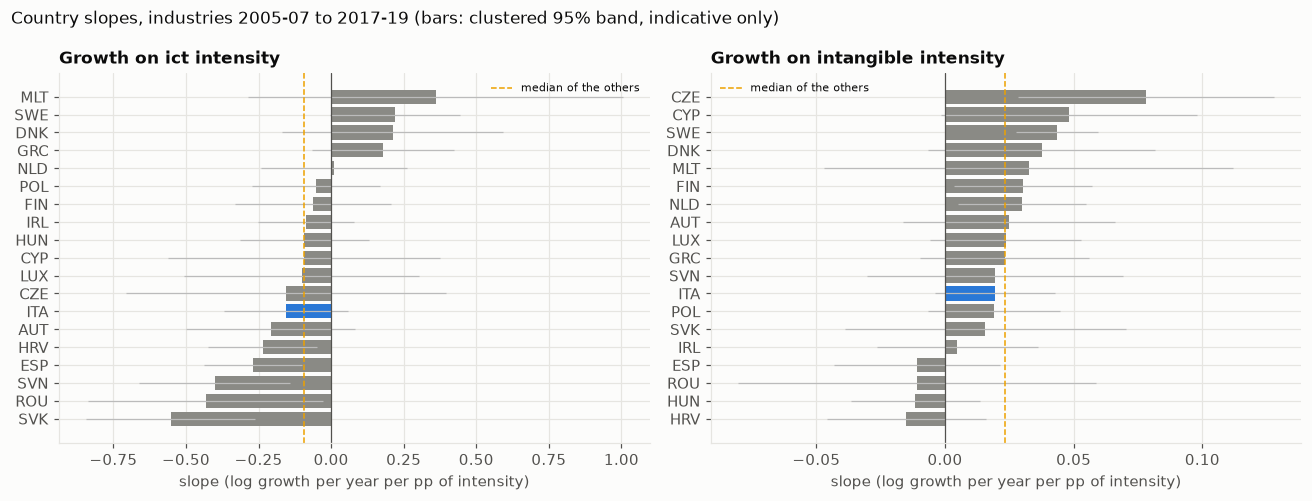

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharex=False)
for ax, k in zip(axes, IP.INTENSITIES, strict=True):
    d = f[f.intensity == k].sort_values("slope")
    cols = [ITALY_C if c == ITALY else "#8a8a85" for c in d.iso3]
    ax.barh(d.iso3, d.slope, color=cols, xerr=1.96 * d.se, error_kw={"lw": 0.8, "ecolor": "#bbb"}); ax.axvline(0, color=INK2, lw=0.8)
    ax.axvline(d.slope[d.iso3 != ITALY].median(), color="#eda100", ls="--", lw=1, label="median of the others")
    ax.set_title(f"Growth on {k} intensity"); ax.set_xlabel("slope (log growth per year per pp of intensity)"); ax.legend(fontsize=7)
fig.suptitle("Country slopes, industries 2005-07 to 2017-19 (bars: clustered 95% band, indicative only)", x=0.01, ha="left", fontsize=11); fig.tight_layout(); save(fig, "28_industry_slopes")

## Takeaways (EU KLEMS intensities, Eurostat 2-digit industries, 2005-2019; descriptive associations only)
- **Coverage.** 19 countries in the full window (20 in the late half), 57 industries each for most (Luxembourg 26, Malta 25, Ireland 45, Sweden 49); Germany, France, Belgium, Portugal and others are out because hours worked are missing at 2-digit level. The industry panel has thousands of rows, but the intensity varies across only ~14 sections, so the effective sample for each slope is small.
- **No country-level pattern survives.** 116 country-window-intensity tests give 12 with permutation p < 0.05 (about 5.8 expected by chance); with false-discovery control over all of them the smallest q is 0.232 and none survives. Spain has the clearest negative ICT slope in the full window (p 0.008; also negative in the early half, but not in the late one) and Sweden and the Czech Republic positive intangible slopes (p 0.010 and 0.034; Czech and Swedish slopes recur in the late half), all below the discovery threshold.
- **Italy sits in the middle.** ICT slope -0.156 against a median of -0.093 for the others (rank 13 of 19 from the top, one-sided p that Italy is this low 0.368); intangible slope 0.019 against 0.023 (rank 12 of 19, p 0.421). Early and late halves give ranks 8 and 13 (ICT) and 6 and 15 (intangible): no stable position. Dropping any one section leaves Italy's rank between 9 and 14 (ICT) and 9 and 13 (intangible).
- **Calibration.** With the intensity shuffled across sections, 3.2% (ICT) and 4.1% (intangible) of country slopes have p < 0.05, so the permutation test is not inflated; the clustered t-test was (15-20%), which is why it is shown only as an indicative band.
- **Reading.** Italy's weak productivity growth is not concentrated in industries that rely more on ICT or intangible capital in other countries: the pattern is not distinguishable from the other countries' slopes. This does not rule out a firm-level or within-section story (notebooks 13 and 23 show where, not why). The benchmark intensity comes from 14 coarse sections, EU KLEMS capital contributions are an imperfect proxy for technology dependence, and R&D or regulation-based intensities were not available.
